# Phase 2: Exploratory data analysis

Run `python -m src.phase2` first. This notebook reads the cleaned, feature-rich listings it produces and saves every chart to `reports/figures/`.

In [1]:
import sys
sys.path.append('..')

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import hypothesis
from src.config import DATA_PROCESSED, DATA_RAW
from src.features import coverage
from src.plots import AQUA, BLUE, MUTED, ORANGE, save, use_style
from src.sources.geo import GEO_DIR

use_style()
df = pd.read_parquet(DATA_PROCESSED / 'listings_features.parquet')
df.shape

Matplotlib is building the font cache; this may take a moment.


(3792, 42)

## 1. Missingness
Which columns have gaps, and how big are they?

,share_filled,missing
address,0.031909,3671
pets_allowed,0.461498,2042
zori_yoy_at_listing,0.645306,1345
zori_at_listing,0.686709,1188
amenities,0.833070,633
zip_median_income,0.908228,348
tract_median_income,0.939082,231
tract_median_rent,0.949631,191
zip_vacancy_rate,0.970200,113
zip_renter_share,0.970200,113


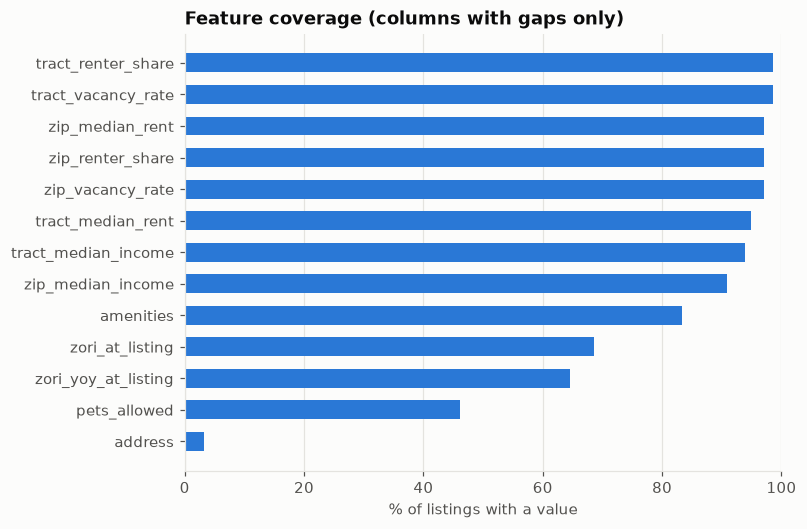

In [2]:
cov = coverage(df)
gaps = cov[cov['share_filled'] < 1]
fig, ax = plt.subplots(figsize=(7, 0.32 * len(gaps) + 1))
ax.barh(gaps.index, gaps['share_filled'] * 100, color=BLUE, height=0.6)
ax.set_xlim(0, 100)
ax.set_xlabel('% of listings with a value')
ax.set_title('Feature coverage (columns with gaps only)')
ax.grid(axis='y', visible=False)
save(fig, 'coverage')
gaps

## 2. Rent distribution
Rents are right-skewed, so models will predict log(rent).

count    3792.0
mean     1386.0
std       423.0
min       500.0
25%      1105.0
50%      1312.0
75%      1574.0
max      4000.0
Name: rent, dtype: float64

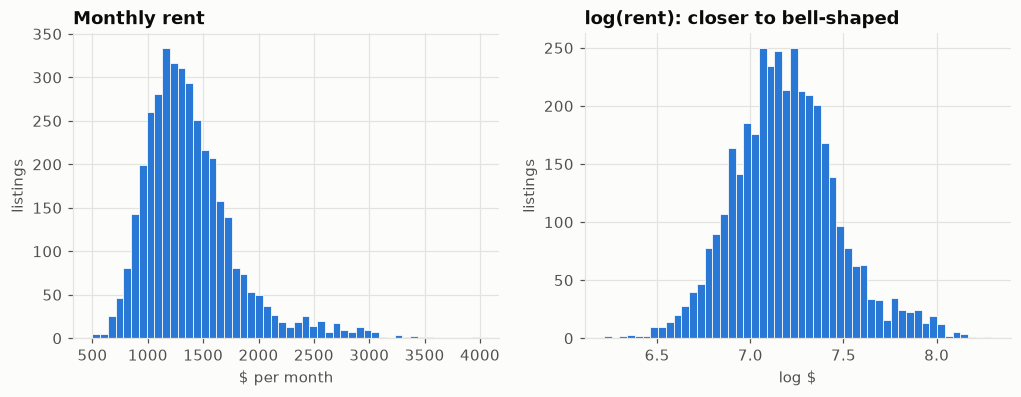

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(df['rent'], bins=50, color=BLUE, edgecolor='white', linewidth=0.5)
axes[0].set_title('Monthly rent')
axes[0].set_xlabel('$ per month')
axes[1].hist(np.log(df['rent']), bins=50, color=BLUE, edgecolor='white', linewidth=0.5)
axes[1].set_title('log(rent): closer to bell-shaped')
axes[1].set_xlabel('log $')
for ax in axes:
    ax.set_ylabel('listings')
save(fig, 'rent_distribution')
df['rent'].describe().round(0)

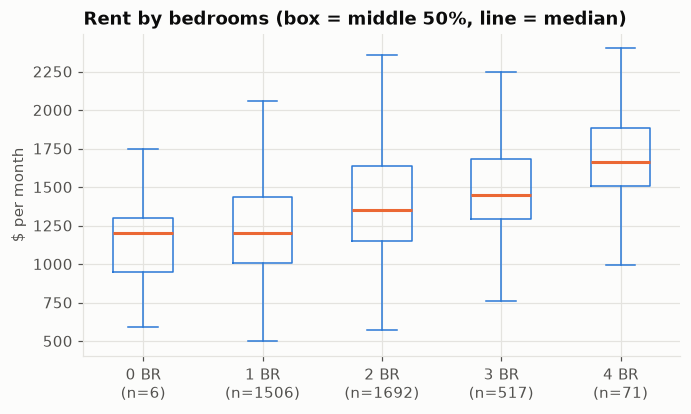

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.8))
groups = [g['rent'].values for _, g in df.groupby('bedrooms')]
labels = [f"{b} BR\n(n={len(g)})" for b, g in df.groupby('bedrooms')]
ax.boxplot(groups, tick_labels=labels, widths=0.5, showfliers=False,
           medianprops={'color': ORANGE, 'linewidth': 2}, boxprops={'color': BLUE},
           whiskerprops={'color': BLUE}, capprops={'color': BLUE})
ax.set_title('Rent by bedrooms (box = middle 50%, line = median)')
ax.set_ylabel('$ per month')
save(fig, 'rent_by_bedrooms')

## 3. Location: downtown and MARTA
Rent per square foot removes most of the size effect, so location patterns show more clearly.

,rent_per_sqft,km_to_downtown,km_to_marta
rent_per_sqft,1.00,-0.44,-0.46
km_to_downtown,-0.44,1.00,0.94
km_to_marta,-0.46,0.94,1.00


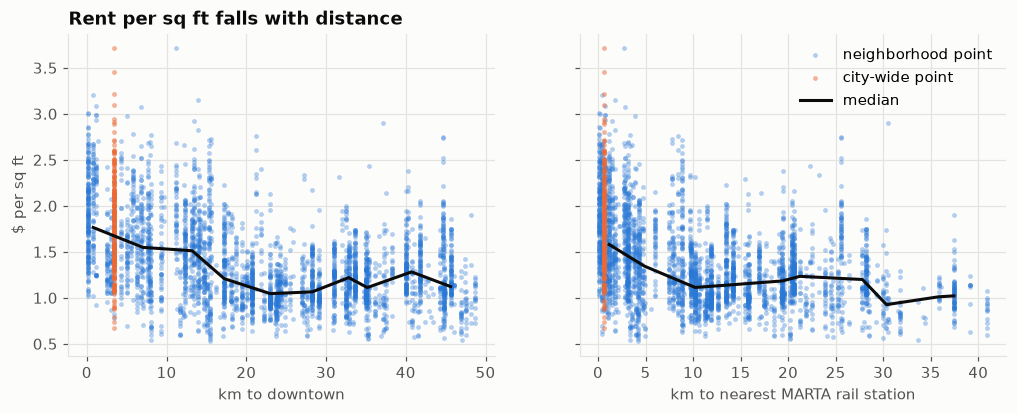

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, col, label in [(axes[0], 'km_to_downtown', 'km to downtown'), (axes[1], 'km_to_marta', 'km to nearest MARTA rail station')]:
    precise = df[~df['coarse_location']]
    ax.scatter(precise[col], precise['rent_per_sqft'], s=10, alpha=0.35, color=BLUE, linewidths=0, label='neighborhood point')
    coarse = df[df['coarse_location']]
    ax.scatter(coarse[col], coarse['rent_per_sqft'], s=10, alpha=0.5, color=ORANGE, linewidths=0, label='city-wide point')
    bins = pd.cut(precise[col], 10)
    trend = precise.groupby(bins, observed=True).agg(x=(col, 'median'), y=('rent_per_sqft', 'median'))
    ax.plot(trend['x'], trend['y'], color='#0b0b0b', label='median')
    ax.set_xlabel(label)
axes[0].set_ylabel('$ per sq ft')
axes[0].set_title('Rent per sq ft falls with distance')
axes[1].legend(loc='upper right')
save(fig, 'rent_vs_distance')
df[['rent_per_sqft', 'km_to_downtown', 'km_to_marta']].corr(method='spearman').round(2)

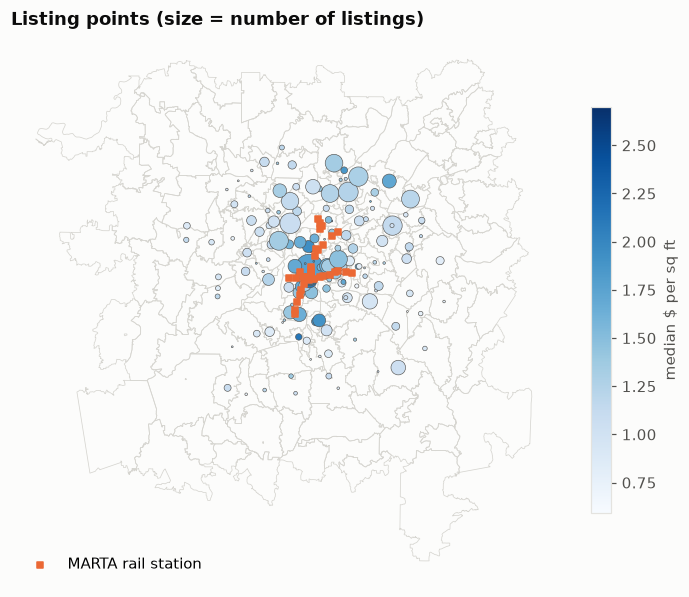

In [6]:
zcta = gpd.read_parquet(GEO_DIR / 'zcta_shapes.parquet')
stations = pd.read_parquet(DATA_RAW / 'marta_stations.parquet')
points = df.groupby(['latitude', 'longitude']).agg(n=('id', 'size'), ppsf=('rent_per_sqft', 'median')).reset_index()
fig, ax = plt.subplots(figsize=(8, 8))
zcta.plot(ax=ax, facecolor='none', edgecolor='#d6d5d0', linewidth=0.5)
sc = ax.scatter(points['longitude'], points['latitude'], s=points['n'] * 1.5, c=points['ppsf'], cmap='Blues',
                edgecolors=MUTED, linewidths=0.4)
ax.scatter(stations['lon'], stations['lat'], marker='s', s=14, color=ORANGE, label='MARTA rail station')
fig.colorbar(sc, ax=ax, shrink=0.6, label='median $ per sq ft')
ax.set_title('Listing points (size = number of listings)')
ax.legend(loc='lower left')
ax.set_axis_off()
save(fig, 'map')

## 4. Which neighborhood signals move with rent?
Spearman correlation with rent per sq ft (rank-based, so outliers matter less).

square_feet           -0.57
km_to_marta           -0.46
bathrooms             -0.44
km_to_downtown        -0.44
hud_safmr             -0.14
tract_median_rent      0.01
tract_median_income    0.05
zip_median_rent        0.07
zip_median_income      0.07
tract_renter_share     0.30
zori_at_listing        0.33
Name: rent_per_sqft, dtype: float64

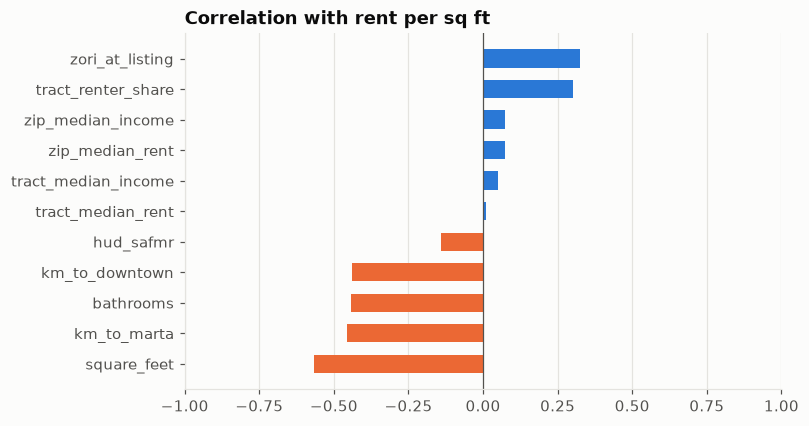

In [7]:
numeric = ['km_to_downtown', 'km_to_marta', 'tract_median_income', 'tract_median_rent', 'tract_renter_share',
           'zip_median_income', 'zip_median_rent', 'hud_safmr', 'zori_at_listing', 'square_feet', 'bathrooms']
corr = df[numeric + ['rent_per_sqft']].corr(method='spearman')['rent_per_sqft'].drop('rent_per_sqft').sort_values()
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(corr.index, corr.values, color=[ORANGE if v < 0 else BLUE for v in corr.values], height=0.6)
ax.axvline(0, color=MUTED, linewidth=0.8)
ax.set_xlim(-1, 1)
ax.set_title('Correlation with rent per sq ft')
ax.grid(axis='y', visible=False)
save(fig, 'correlations')
corr.round(2)

## 5. Timing
Listings arrive in a few bursts. The newest 20% (the Phase 3 test set) will be the late-2019 listings.

newest-20% cutoff: 2019-09-18 03:19:41.800000


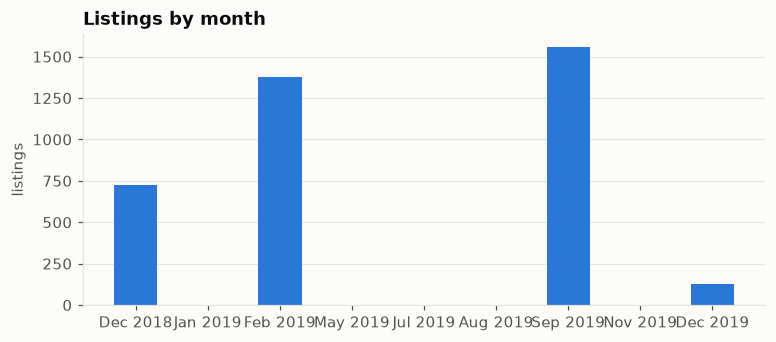

In [8]:
monthly = df.set_index('listed_at').resample('MS').size()
monthly = monthly[monthly > 0]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(monthly.index.strftime('%b %Y'), monthly.values, color=BLUE, width=0.6)
ax.set_title('Listings by month')
ax.set_ylabel('listings')
ax.grid(axis='x', visible=False)
save(fig, 'listings_by_month')
cutoff = df['listed_at'].quantile(0.8)
print('newest-20% cutoff:', cutoff)

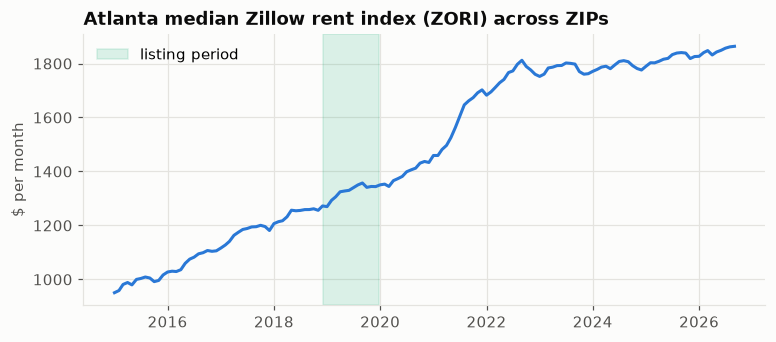

In [9]:
zori = pd.read_parquet(DATA_RAW / 'zillow_zori.parquet')
metro = zori.groupby('month')['zori'].median()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(metro.index, metro.values, color=BLUE)
ax.axvspan(df['listed_at'].min(), df['listed_at'].max(), color=AQUA, alpha=0.15, label='listing period')
ax.set_title('Atlanta median Zillow rent index (ZORI) across ZIPs')
ax.set_ylabel('$ per month')
ax.legend(loc='upper left')
save(fig, 'zori_trend')

## 6. Hypothesis test: 3-4 unit buildings
Census PUMS renters, 2022-2024. Each dot is the rent difference vs 5+ unit buildings after controls; lines are 95% confidence intervals. Full table: `reports/phase2_findings.md`.

Holding bedrooms, rooms, building age, location (PUMA) and survey year fixed, units in 3-4 unit buildings rent for 15.3% less than units in 5+ unit buildings (difference -15.3%, 95% CI -21.2% to -9.0%, p = 6.71e-06); this is statistically significant at the 5% level.


,building,coef,pct_vs_5plus,ci_low_pct,ci_high_pct,p_value,spec,n,r2
0,1 unit,0.013,1.316,-2.570,5.357,0.512,"Main: weighted, robust SE",11700,0.208
1,2 units,-0.193,-17.515,-25.594,-8.560,0.000,"Main: weighted, robust SE",11700,0.208
2,3-4 units,-0.166,-15.332,-21.248,-8.970,0.000,"Main: weighted, robust SE",11700,0.208
3,1 unit,0.021,2.168,-1.254,5.709,0.217,"Unweighted, robust SE",11700,0.214
4,2 units,-0.151,-13.992,-20.367,-7.107,0.000,"Unweighted, robust SE",11700,0.214
5,3-4 units,-0.130,-12.209,-16.316,-7.900,0.000,"Unweighted, robust SE",11700,0.214
6,1 unit,0.013,1.316,-4.363,7.332,0.657,"Weighted, SE clustered by PUMA",11700,0.208
7,2 units,-0.193,-17.515,-26.947,-6.865,0.002,"Weighted, SE clustered by PUMA",11700,0.208
8,3-4 units,-0.166,-15.332,-21.675,-8.474,0.000,"Weighted, SE clustered by PUMA",11700,0.208
9,1 unit,0.055,5.616,2.316,9.022,0.001,Gross rent (incl. utilities),11700,0.247


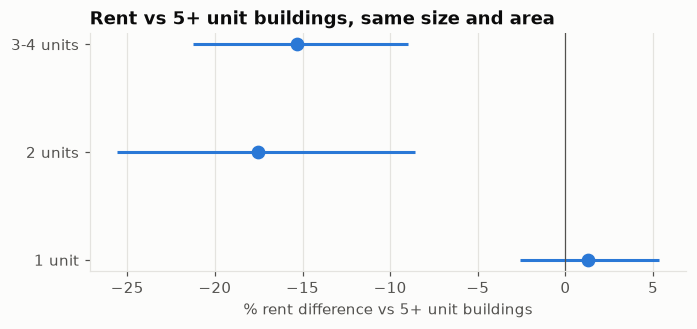

In [10]:
pums = hypothesis.prepare(pd.read_parquet(DATA_RAW / 'pums_renters.parquet'))
effects = hypothesis.run_specs(pums)
print(hypothesis.headline(effects))
main = effects[effects['spec'] == next(iter(hypothesis.SPECS))].set_index('building').loc[['1 unit', '2 units', '3-4 units']]
fig, ax = plt.subplots(figsize=(7, 2.8))
y = np.arange(len(main))
ax.errorbar(main['pct_vs_5plus'], y, xerr=[main['pct_vs_5plus'] - main['ci_low_pct'], main['ci_high_pct'] - main['pct_vs_5plus']],
            fmt='o', color=BLUE, ecolor=BLUE, elinewidth=2, capsize=0, markersize=8)
ax.axvline(0, color=MUTED, linewidth=0.8)
ax.set_yticks(y, main.index)
ax.set_xlabel('% rent difference vs 5+ unit buildings')
ax.set_title('Rent vs 5+ unit buildings, same size and area')
ax.grid(axis='y', visible=False)
save(fig, 'hypothesis_effects')
effects.round(3)

## 7. Summary

**Data.** Cleaning took 4,299 raw listings down to 3,792 (reposts, mislabeled studios, size and rent/sq ft outliers, unfixable locations). Locations are neighborhood-level only: 157 map points, 233 listings on a city-wide fallback point.

**Rent.** Median rent is \$1,312 (middle half \$1,105 to \$1,574) and right-skewed, so models will predict log(rent). Median rent climbs from \$1,204 (1 BR) to \$1,664 (4 BR), but rent per sq ft falls from \$1.54 to \$0.77. Bigger units cost less per foot.

**Location.** Rent per sq ft falls with distance: Spearman -0.44 vs km to downtown and -0.46 vs km to the nearest MARTA rail station. The two distances are almost the same signal (0.94), so one is enough in a linear model. Most of the drop happens in the first ~15 km.

**Neighborhood stats.** Census tract and ZIP income barely track rent per sq ft (about 0.05). ZORI (0.33) and renter share (0.30) do better. The Census figures are 2020-2024 while listings are 2018-2019, so these are relative signals only.

**Gaps.** ZORI is missing for 31% of listings (metro fallback planned for Phase 4), tract income for 6%, ZIP income for 9%.

**Timing.** Listings come in bursts. The newest 20% (after 2019-09-18) becomes the Phase 3 test set.

**Hypothesis.** In Census PUMS (11,700 renter households, 2022-2024), units in 3-4 unit buildings rent for **15.3% less** than units in 5+ unit buildings after controlling for bedrooms, rooms, building age, PUMA and year (95% CI -21.2% to -9.0%, p < 0.001). The discount holds in every robustness check (unweighted -12.2%, PUMA-clustered SE -15.3%, gross rent -10.3%). 2-unit buildings show a similar discount (-17.5%); single-family homes show none (+1.3%, not significant).